In [2]:
# import libraries and configure paths

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Dataset paths
BASE_DIR = Path("..")

TRAIN_PATH = BASE_DIR / "datasets" / "train"
TEST_PATH = BASE_DIR / "datasets" / "student_test"

# Results directory
RESULTS_PATH = BASE_DIR / "results" / "eda"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

print("Training path exists:", TRAIN_PATH.exists())
print("Student-test path exists:", TEST_PATH.exists())
print("Results directory:", RESULTS_PATH)

Training path exists: True
Student-test path exists: True
Results directory: ../results/eda


In [3]:
# count trips

train_trips = sorted(
    [p for p in TRAIN_PATH.iterdir() if p.is_dir()]
)

test_trips = sorted(
    [p for p in TEST_PATH.iterdir() if p.is_dir()]
)

print("Training trips:", len(train_trips))
print("Student-test trips:", len(test_trips))
print("Total trips:", len(train_trips) + len(test_trips))

Training trips: 80
Student-test trips: 10
Total trips: 90


# Sample Analysis of trip 00000001

In [10]:
# inspect one trip

sample_trip = train_trips[0]

print("Sample trip:", sample_trip.name)
print("\nFiles inside:")

for file in sorted(sample_trip.iterdir()):
    print(file.name, "-", file.stat().st_size, "bytes")

Sample trip: 00000001

Files inside:
00000001.arcs - 1948474 bytes
00000001.nodes - 1687371 bytes
00000001.route - 3119 bytes
00000001.track - 40975 bytes


In [11]:
# inspect the first 5 rows of each file

sample_trip = train_trips[0]
trip_id = sample_trip.name

extensions = [".track", ".nodes", ".arcs", ".route"]

for ext in extensions:
    file_path = sample_trip / f"{trip_id}{ext}"

    print(f"\nFILE: {file_path.name}")

    data = pd.read_csv(
        file_path,
        sep=r"\s+",
        header=None,
        nrows=5
    )

    print(data)
    print("\nShape of first 5 rows:", data.shape)


FILE: 00000001.track
          0          1    2
0  8.595203  49.844053  1.0
1  8.595294  49.844441  2.0
2  8.595352  49.844883  3.0
3  8.595390  49.845379  4.0
4  8.595587  49.845750  5.0

Shape of first 5 rows: (5, 3)

FILE: 00000001.nodes
          0          1
0  8.581679  49.857880
1  8.584637  49.858295
2  8.580173  49.858567
3  8.584392  49.859119
4  8.584935  49.857396

Shape of first 5 rows: (5, 2)

FILE: 00000001.arcs
   0      1
0  0    281
1  0      1
2  0      5
3  1      0
4  1  40750

Shape of first 5 rows: (5, 2)

FILE: 00000001.route
        0
0    2641
1   64973
2  133948
3  133949
4  139208

Shape of first 5 rows: (5, 1)


In [12]:
# load the complete GPS trajectory

track_file = sample_trip / f"{trip_id}.track"

track = pd.read_csv(
    track_file,
    sep=r"\s+",
    header=None,
    names=["longitude", "latitude", "timestamp"]
)

print("Trip ID:", trip_id)
print("Total GPS observations:", len(track))

print("\nFirst 10 observations:")
display(track.head(10))

print("\nData types:")
print(track.dtypes)

print("\nStatistical summary:")
display(track.describe())

Trip ID: 00000001
Total GPS observations: 1315

First 10 observations:


,longitude,latitude,timestamp
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0
5,8.595555,49.846167,6.0
6,8.595744,49.846565,7.0
7,8.595733,49.846931,8.0
8,8.595878,49.847374,9.0
9,8.595849,49.847684,10.0



Data types:
longitude    float64
latitude     float64
timestamp    float64
dtype: object

Statistical summary:


,longitude,latitude,timestamp
count,1315.000000,1315.000000,1315.000000
mean,8.605599,50.088368,661.000760
std,0.016356,0.117561,384.387699
min,8.570524,49.844053,1.000000
25%,8.596061,49.987136,329.500000
50%,8.603564,50.128292,658.000000
75%,8.612624,50.199064,988.500000
max,8.647860,50.211882,1358.000000


In [13]:
# check for missing values and duplicates

# Missing values
print("Missing values:")
print(track.isnull().sum())

# Duplicate timestamps
print("\nDuplicate timestamps:")
print(track["timestamp"].duplicated().sum())

# Duplicate GPS observations
print("\nDuplicate GPS rows:")
print(track.duplicated().sum())

Missing values:
longitude    0
latitude     0
timestamp    0
dtype: int64

Duplicate timestamps:
0

Duplicate GPS rows:
0


Timestamp gap statistics:


count    1314.000000
mean        1.032725
std         0.446355
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        16.000000
Name: timestamp, dtype: float64


Number of gaps greater than 5 seconds: 1
Number of zero or negative gaps: 0


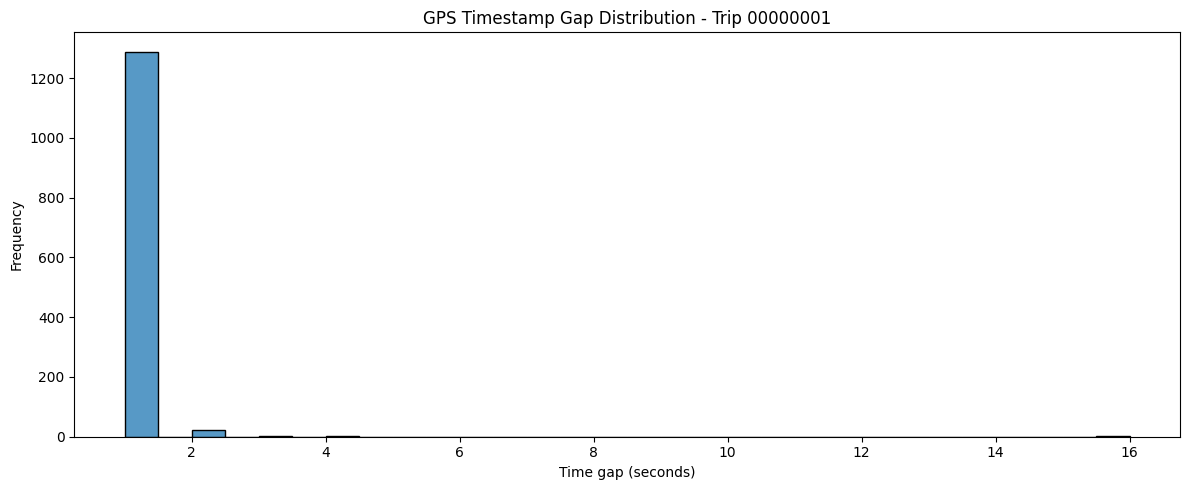

In [14]:
# calculate time difference between consecutive observations

time_gaps = track["timestamp"].diff().dropna()

print("Timestamp gap statistics:")
display(time_gaps.describe())

print("\nNumber of gaps greater than 5 seconds:",
      (time_gaps > 5).sum())

print("Number of zero or negative gaps:",
      (time_gaps <= 0).sum())

# Plot timestamp gaps
plt.figure(figsize=(12, 5))

sns.histplot(time_gaps, bins=30)

plt.title(f"GPS Timestamp Gap Distribution - Trip {trip_id}")
plt.xlabel("Time gap (seconds)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [15]:
# find unusually large timestamp gaps

track["time_gap"] = track["timestamp"].diff()

large_gaps = track[track["time_gap"] > 5]

print("Unusually large GPS gaps:")
display(large_gaps)

# Show the observation immediately before each large gap
for idx in large_gaps.index:
    print(f"\nGap occurs between observations {idx-1} and {idx}:")
    display(track.iloc[[idx-1, idx]])

Unusually large GPS gaps:


,longitude,latitude,timestamp,time_gap
1221,8.582965,50.200698,1250.0,16.0



Gap occurs between observations 1220 and 1221:


,longitude,latitude,timestamp,time_gap
1220,8.583169,50.200578,1234.0,2.0
1221,8.582965,50.200698,1250.0,16.0


# Analysis of All Trips

In [ ]:
# analyise all trips

def analyse_track(trip_path, partition):

    trip_id = trip_path.name
    track_file = trip_path / f"{trip_id}.track"

    track_data = pd.read_csv(
        track_file,
        sep=r"\s+",
        header=None,
        names=["longitude", "latitude", "timestamp"]
    )

    gaps = track_data["timestamp"].diff().dropna()

    return {
        "partition": partition,
        "trip_id": trip_id,
        "gps_observations": len(track_data),

        "missing_values": track_data.isnull().sum().sum(),
        "duplicate_timestamps": track_data["timestamp"].duplicated().sum(),
        "duplicate_rows": track_data.duplicated().sum(),

        "duration": (
            track_data["timestamp"].iloc[-1]
            - track_data["timestamp"].iloc[0]
            if len(track_data) > 1 else 0
        ),

        "mean_gap": gaps.mean(),
        "median_gap": gaps.median(),
        "max_gap": gaps.max(),

        "gaps_over_5_seconds": (gaps > 5).sum(),
        "non_positive_gaps": (gaps <= 0).sum()
    }


# Analyse all training trips
all_results = []

for trip in train_trips:
    all_results.append(analyse_track(trip, "train"))

# Analyse all student-test trips
for trip in test_trips:
    all_results.append(analyse_track(trip, "student_test"))


# Convert results into a DataFrame
df_gps = pd.DataFrame(all_results)

print("GPS analysis completed!")
print("Total trips analysed:", len(df_gps))

display(df_gps.head())

GPS analysis completed!
Total trips analysed: 90


,partition,trip_id,gps_observations,missing_values,duplicate_timestamps,duplicate_rows,duration,mean_gap,median_gap,max_gap,gaps_over_5_seconds,non_positive_gaps
0,train,00000001,1315,0,0,0,1357.000,1.032725,1.0,16.0,1,0
1,train,00000002,7243,0,0,0,8933.156,1.233521,1.0,160.0,78,0
2,train,00000003,821,0,0,0,823.000,1.003659,1.0,2.0,0,0
3,train,00000004,1064,0,0,0,5217.000,4.907808,1.0,51.0,320,0
4,train,00000005,1045,0,0,0,1044.000,1.000000,1.0,1.0,0,0


In [ ]:
# generate dataset-wide statistics

# Summary statistics for each partition

summary = df_gps.groupby("partition").agg({
    "gps_observations": ["count", "mean", "median", "min", "max"],
    "duration": ["mean", "median", "min", "max"],
    "mean_gap": ["mean", "median"],
    "max_gap": ["mean", "max"],
    "gaps_over_5_seconds": "sum",
    "missing_values": "sum",
    "duplicate_timestamps": "sum",
    "duplicate_rows": "sum"
})

display(summary)

gps_observations                                    duration  \
                        count       mean  median  min    max         mean   
partition                                                                   
student_test               10  1916.0000  1420.0  262   3958  2025.000000   
train                      80  2605.2125  1529.0  361  19313  5680.404487   

                                          mean_gap           max_gap  \
                 median    min       max      mean    median    mean   
partition                                                              
student_test  1809.5000  265.0    4000.0  1.090549  1.000677    25.5   
train         1710.0015  451.0  154030.0  5.101888  1.058959  2706.4   

                       gaps_over_5_seconds missing_values  \
                   max                 sum            sum   
partition                                                   
student_test     210.0                  44              0   
train         153064.0                1216              0   

             duplicate_timestamps duplicate_rows  
                              sum            sum  
partition                                         
student_test                    0              0  
train                           0              0

In [18]:
# save your results

# Save trip-level GPS statistics
df_gps.to_csv(
    RESULTS_PATH / "gps_trip_statistics.csv",
    index=False
)

# Save partition-level summary
summary.to_csv(
    RESULTS_PATH / "gps_partition_summary.csv"
)

print("Saved successfully!")
print("Location:", RESULTS_PATH)

Saved successfully!
Location: ../results/eda
